In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 2
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [3]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 26.17it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:03<00:00, 106.28it/s]


In [4]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:03<00:00, 140.69it/s]


In [5]:
import pandas as pd

In [6]:
DATA = DATA.drop(columns="OS")

# NMF

In [13]:
from TractDensityComponents import TD_PCA
from components import Projections

normalization = None#'min_max'
save_dir = "results/"
n_components = 100

# Masking
td_pca = TD_PCA(maps_all, T1, binary_mask=T1_brain, n_components=n_components)
X = td_pca.training_maps

from sklearn.decomposition import NMF, MiniBatchNMF
import sklearn


sklearn.set_config(transform_output="default")

model = NMF(n_components=n_components, init='random', random_state=0, max_iter=10, verbose=1)
# model = MiniBatchNMF(n_components=n_components, init='random', random_state=0, max_iter=20, verbose=1, batch_size=128)
W = model.fit_transform(X)
H = model.components_

INFO:	TD maps were masked.
violation: 1.0
violation: 1.7337764600082501
violation: 0.3082897936471642
violation: 0.19049939767186427
violation: 0.13226825653611252
violation: 0.09659748151967468
violation: 0.07575754659042538
violation: 0.06251730970516302
violation: 0.052442076754489184
violation: 0.045130063326043995


/home/joan/.conda/envs/neuro/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 10 reached. Increase it to improve convergence.
  warnings.warn(


In [8]:
err = model.reconstruction_err_
print(f"Model reconstruction error for 10 components {err:.4f}")

import numpy as np

total_norm = np.linalg.norm(X)
relative_error = err / total_norm

print(f"Relative error: {relative_error:.4%}")
print(f"R^2: {1 - (err/total_norm)**2:.4%}")

Model reconstruction error for 10 components 215873.5186
Relative error: 22.2282%
R^2: 95.0591%


In [16]:
new_cols_df = pd.DataFrame(W[:, :n_components], columns=[f"Comp. {i}" for i in range(n_components)], index=DATA.index)
new_cols_df.head()

,Comp. 0,Comp. 1,Comp. 2,Comp. 3,Comp. 4,Comp. 5,Comp. 6,Comp. 7,Comp. 8,Comp. 9,...,Comp. 90,Comp. 91,Comp. 92,Comp. 93,Comp. 94,Comp. 95,Comp. 96,Comp. 97,Comp. 98,Comp. 99
0,0.000000,3.927636,0.000000,0.000000,1.128190,0.000000,0.053723,0.000000,5.513191,0.000000,...,0.000000,0.000000,3.682962,1.406887,0.00000,0.000000,7.447772,0.000000,0.360366,0.000000
1,0.292414,0.000000,0.000000,5.537050,0.000000,0.005631,0.000000,0.090218,0.000000,0.000000,...,0.000000,0.000000,0.558742,0.000000,1.87796,0.000000,7.712888,0.000000,0.000000,0.000000
2,1.436869,0.000000,0.000000,0.000000,0.000000,2.418526,0.000000,0.228326,2.194592,0.611871,...,1.201357,0.000000,0.000000,0.000000,0.00000,0.474067,0.000000,0.146495,0.000000,1.725361
3,15.492223,0.000000,30.186213,0.000000,0.000000,1.087930,0.429946,0.000000,3.652727,18.265376,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.661241,0.000000,0.000000,0.000000,1.836090
4,0.000000,22.806185,0.000000,1.379006,7.806841,0.000000,0.000000,0.000000,2.674572,0.000000,...,0.004014,3.900536,0.666296,0.653406,0.86144,0.000000,6.867467,0.000000,2.313954,0.000000


In [17]:
column_names = [f'NMF_comp_{i}' for i in range(W.shape[1])]
df_nmf_weights = pd.DataFrame(W, columns=column_names)
df = pd.concat([DATA.reset_index(drop=True), df_nmf_weights], axis=1)

df.head()

,ID,sex,age,site,volume,ltdi,tdi,OS,status,OS (corrected),...,NMF_comp_90,NMF_comp_91,NMF_comp_92,NMF_comp_93,NMF_comp_94,NMF_comp_95,NMF_comp_96,NMF_comp_97,NMF_comp_98,NMF_comp_99
0,UCSF-PDGM-009,F,68.0,0,157.513875,4.584943,125.455774,389.0,1,389.0,...,0.000000,0.000000,3.682962,1.406887,0.00000,0.000000,7.447772,0.000000,0.360366,0.000000
1,UCSF-PDGM-004,M,66.0,0,58.872375,2.269988,90.082312,1303.0,1,1303.0,...,0.000000,0.000000,0.558742,0.000000,1.87796,0.000000,7.712888,0.000000,0.000000,0.000000
2,UCSF-PDGM-008,M,70.0,0,235.057500,5.576720,106.265873,185.0,1,185.0,...,1.201357,0.000000,0.000000,0.000000,0.00000,0.474067,0.000000,0.146495,0.000000,1.725361
3,UCSF-PDGM-011,F,68.0,0,172.138125,6.746218,132.010322,133.0,0,133.0,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.661241,0.000000,0.000000,0.000000,1.836090
4,UCSF-PDGM-014,F,64.0,0,271.585125,6.527491,95.183594,313.0,1,313.0,...,0.004014,3.900536,0.666296,0.653406,0.86144,0.000000,6.867467,0.000000,2.313954,0.000000


Concordance Index: 0.6825


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -3955.60
         time fit was run = 2026-03-04 18:30:44 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
age          2.73     15.37      0.30            2.14            3.33                8.48               27.87
NMF_comp_0   0.52      1.68      0.60           -0.66            1.70                0.52                5.48
NMF_comp_1  -0.55      0.58      0.62           -1.78            0.67                0.17                1.96
NMF_comp_2   0.79      2.21      0.36            0.09            1.50                1.09                4.49
NMF_comp_3  -0.33      0.72      0.46           -1.22            0.56                0.29                1.76
NMF_comp_4  -0.25      0.78      0.50           -1.23            0.73                0.29                2.07
NMF_comp_5  -0.14      0.87      0.39           -0.91            0.63                0.40                1.88
NMF_comp_6   0.13      1.14      0.38           -0.61            0.88                0.54                2.40
NMF_comp_7   0.20      1.22      0.39           -0.57            0.97                0.57                2.63
NMF_comp_8  -0.03      0.97      0.33           -0.69            0.62                0.50                1.85
NMF_comp_9  -0.07      0.93      0.36           -0.78            0.64                0.46                1.89
NMF_comp_10 -0.03      0.97      0.38           -0.77            0.72                0.46                2.05
NMF_comp_11  0.05      1.05      0.44           -0.80            0.90                0.45                2.46
NMF_comp_12 -0.72      0.49      0.37           -1.44            0.01                0.24                1.01
NMF_comp_13 -0.78      0.46      0.42           -1.59            0.04                0.20                1.05
NMF_comp_14 -0.18      0.83      0.32           -0.81            0.45                0.44                1.56
NMF_comp_15 -0.27      0.76      0.33           -0.91            0.37                0.40                1.45
NMF_comp_16  0.48      1.62      0.37           -0.24            1.20                0.79                3.32
NMF_comp_17 -0.07      0.94      0.35           -0.74            0.61                0.48                1.84
NMF_comp_18 -0.82      0.44      0.38           -1.57           -0.07                0.21                0.93
NMF_comp_19 -0.58      0.56      0.50           -1.56            0.40                0.21                1.50
NMF_comp_20  1.59      4.92      0.37            0.86            2.33                2.37               10.24
NMF_comp_21 -0.04      0.97      0.37           -0.77            0.70                0.46                2.01
NMF_comp_22 -0.31      0.73      0.39           -1.07            0.45                0.34                1.57
NMF_comp_23 -0.45      0.64      0.58           -1.59            0.69                0.20                1.98
NMF_comp_24  1.08      2.93      0.42            0.25            1.91                1.28                6.74
NMF_comp_25 -0.21      0.81      0.53           -1.24            0.83                0.29                2.30
NMF_comp_26  1.16      3.20      0.42            0.33            1.99                1.39                7.35
NMF_comp_27  0.31      1.37      0.47           -0.61            1.23                0.54                3.43
NMF_comp_28  0.19      1.21      0.44           -0.67            1.05                0.51                2.85
NMF_comp_29  1.56      4.78      0.59        

<Axes: title={'center': 'NMF, n_components: 100. Concordance Index: 0.6825'}, xlabel='log(HR) (95% CI)'>

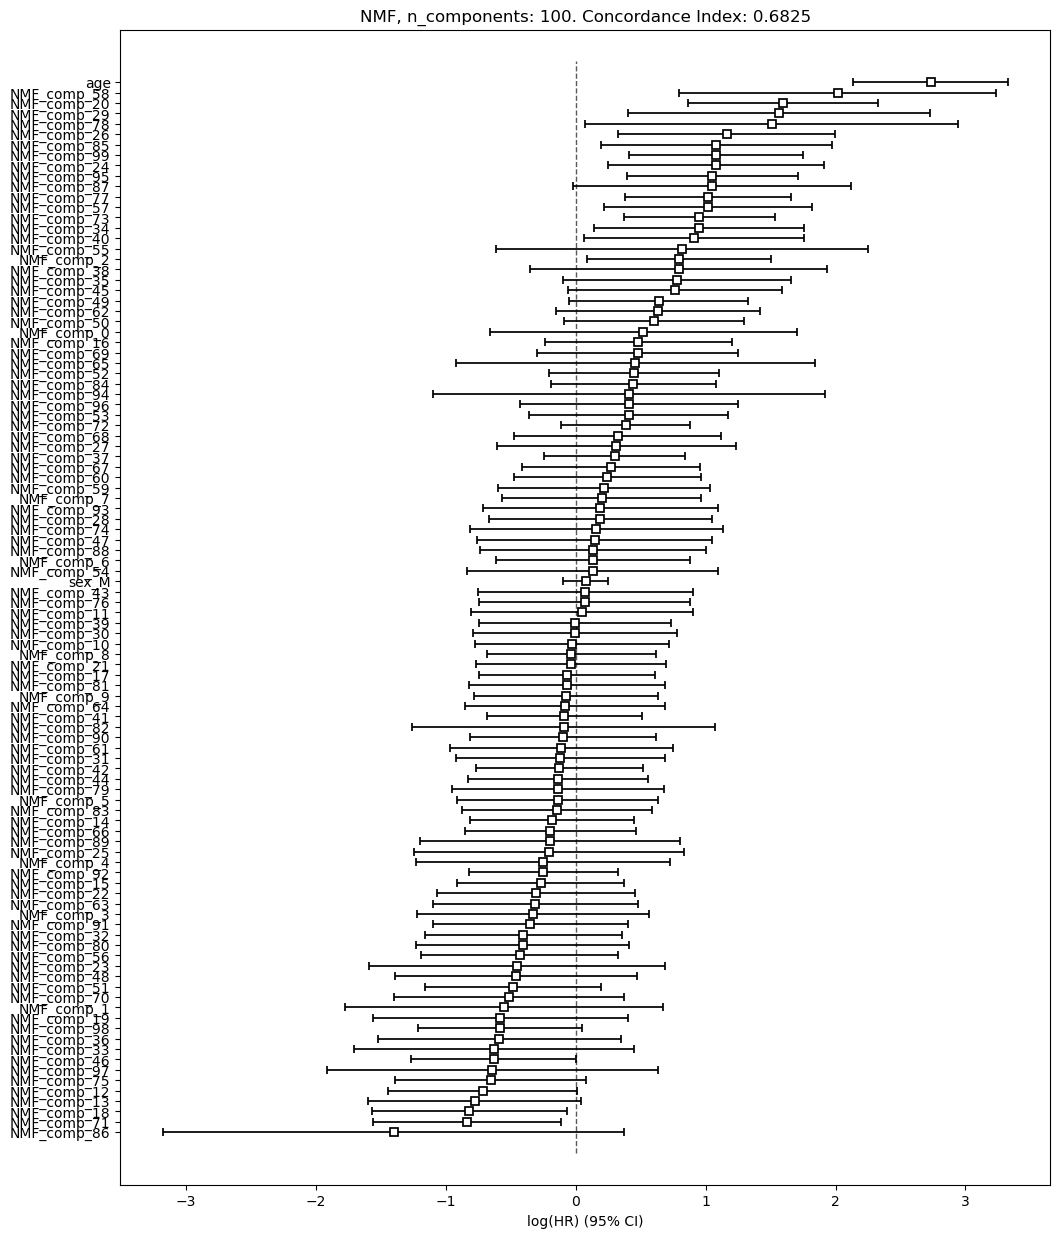

In [18]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 15))
ax.set_title(f"NMF, n_components: {n_components}. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

In [21]:
from nmf_projections import NMFProjections


nmf_proj = NMFProjections(W, H, T1, T1_brain)
output_dir = "results-NMF"
os.makedirs(output_dir, exist_ok=True)
output_filename = "nmf_loadings_4d.nii.gz"

nmf_proj.components_to_brain(
    save_dir=output_dir, 
    filename=output_filename, 
    verbose=True
)

DEBUG: components shape: (100, 265341)
DEBUG: n_components_: 100
DEBUG: expected total size: 106859200
INFO:	Unmasking NMF loadings into 3D space...
INFO:	Saved 4D NIfTI components at results-NMF/nmf_loadings_4d.nii.gz


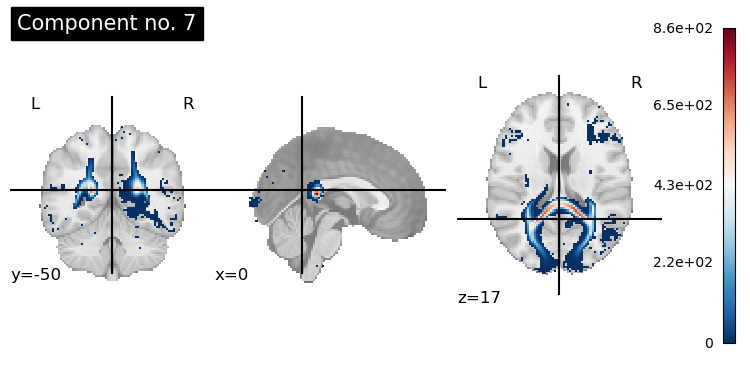

Max value in component 7: 861.2129516601562
Min value (should be 0 for NMF): 0.0


In [22]:
from nilearn import image

from nilearn import plotting

img_path = "results-NMF/nmf_loadings_4d.nii.gz"

no = 7
fourth_comp = image.index_img(img_path, no)

plotting.plot_stat_map(fourth_comp, title=f"Component no. {no}", threshold=0)
plotting.show()

data = fourth_comp.get_fdata()
print(f"Max value in component {no}: {data.max()}")
print(f"Min value (should be 0 for NMF): {data.min()}")

In [ ]:
from nmf_projections import NMFProjections
from nilearn import image, plotting


nmf_proj = NMFProjections(W, H, T1, T1_brain)
output_dir = "results-NMF"
os.makedirs(output_dir, exist_ok=True)
output_filename = "nmf_loadings_4d.nii.gz"

nmf_proj.components_to_brain(
    save_dir=output_dir, 
    filename=output_filename, 
    verbose=True
)

import matplotlib.pyplot as plt
from nilearn import image, plotting

img_path = "results/nmf/nmf_loadings_4d.nii.gz"
n_components = 10

n_cols = 3
n_rows = (n_components + n_cols - 1) // n_cols

fig = plt.figure(figsize=(18, 4 * n_rows))

for i in range(n_components):
    comp_img = image.index_img(img_path, i)
    vmax = comp_img.get_fdata().max()
    
    ax = fig.add_subplot(n_rows, n_cols, i + 1)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Comp {i} | Max: {vmax:.3f}", 
        threshold=0.01,
        axes=ax, 
        colorbar=True,
        display_mode='z', 
        cut_coords=1,
        annotate=False
    )

plt.subplots_adjust(hspace=0.3, wspace=0.1)
plotting.show()

In [24]:
import numpy as np


corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.99)]

print("Colinearity suspects:", to_drop)

constant_cols = [col for col in X.columns if X[col].nunique() <= 1]
print(f"Columns to delete: {constant_cols}")

X = X.drop(columns=constant_cols)

pd.isnull(df).iloc[0]

Colinearity suspects: []
Columns to delete: []


ID                False
sex               False
age               False
status            False
OS (corrected)    False
                  ...  
NMF_comp_95       False
NMF_comp_96       False
NMF_comp_97       False
NMF_comp_98       False
NMF_comp_99       False
Name: 0, Length: 105, dtype: bool

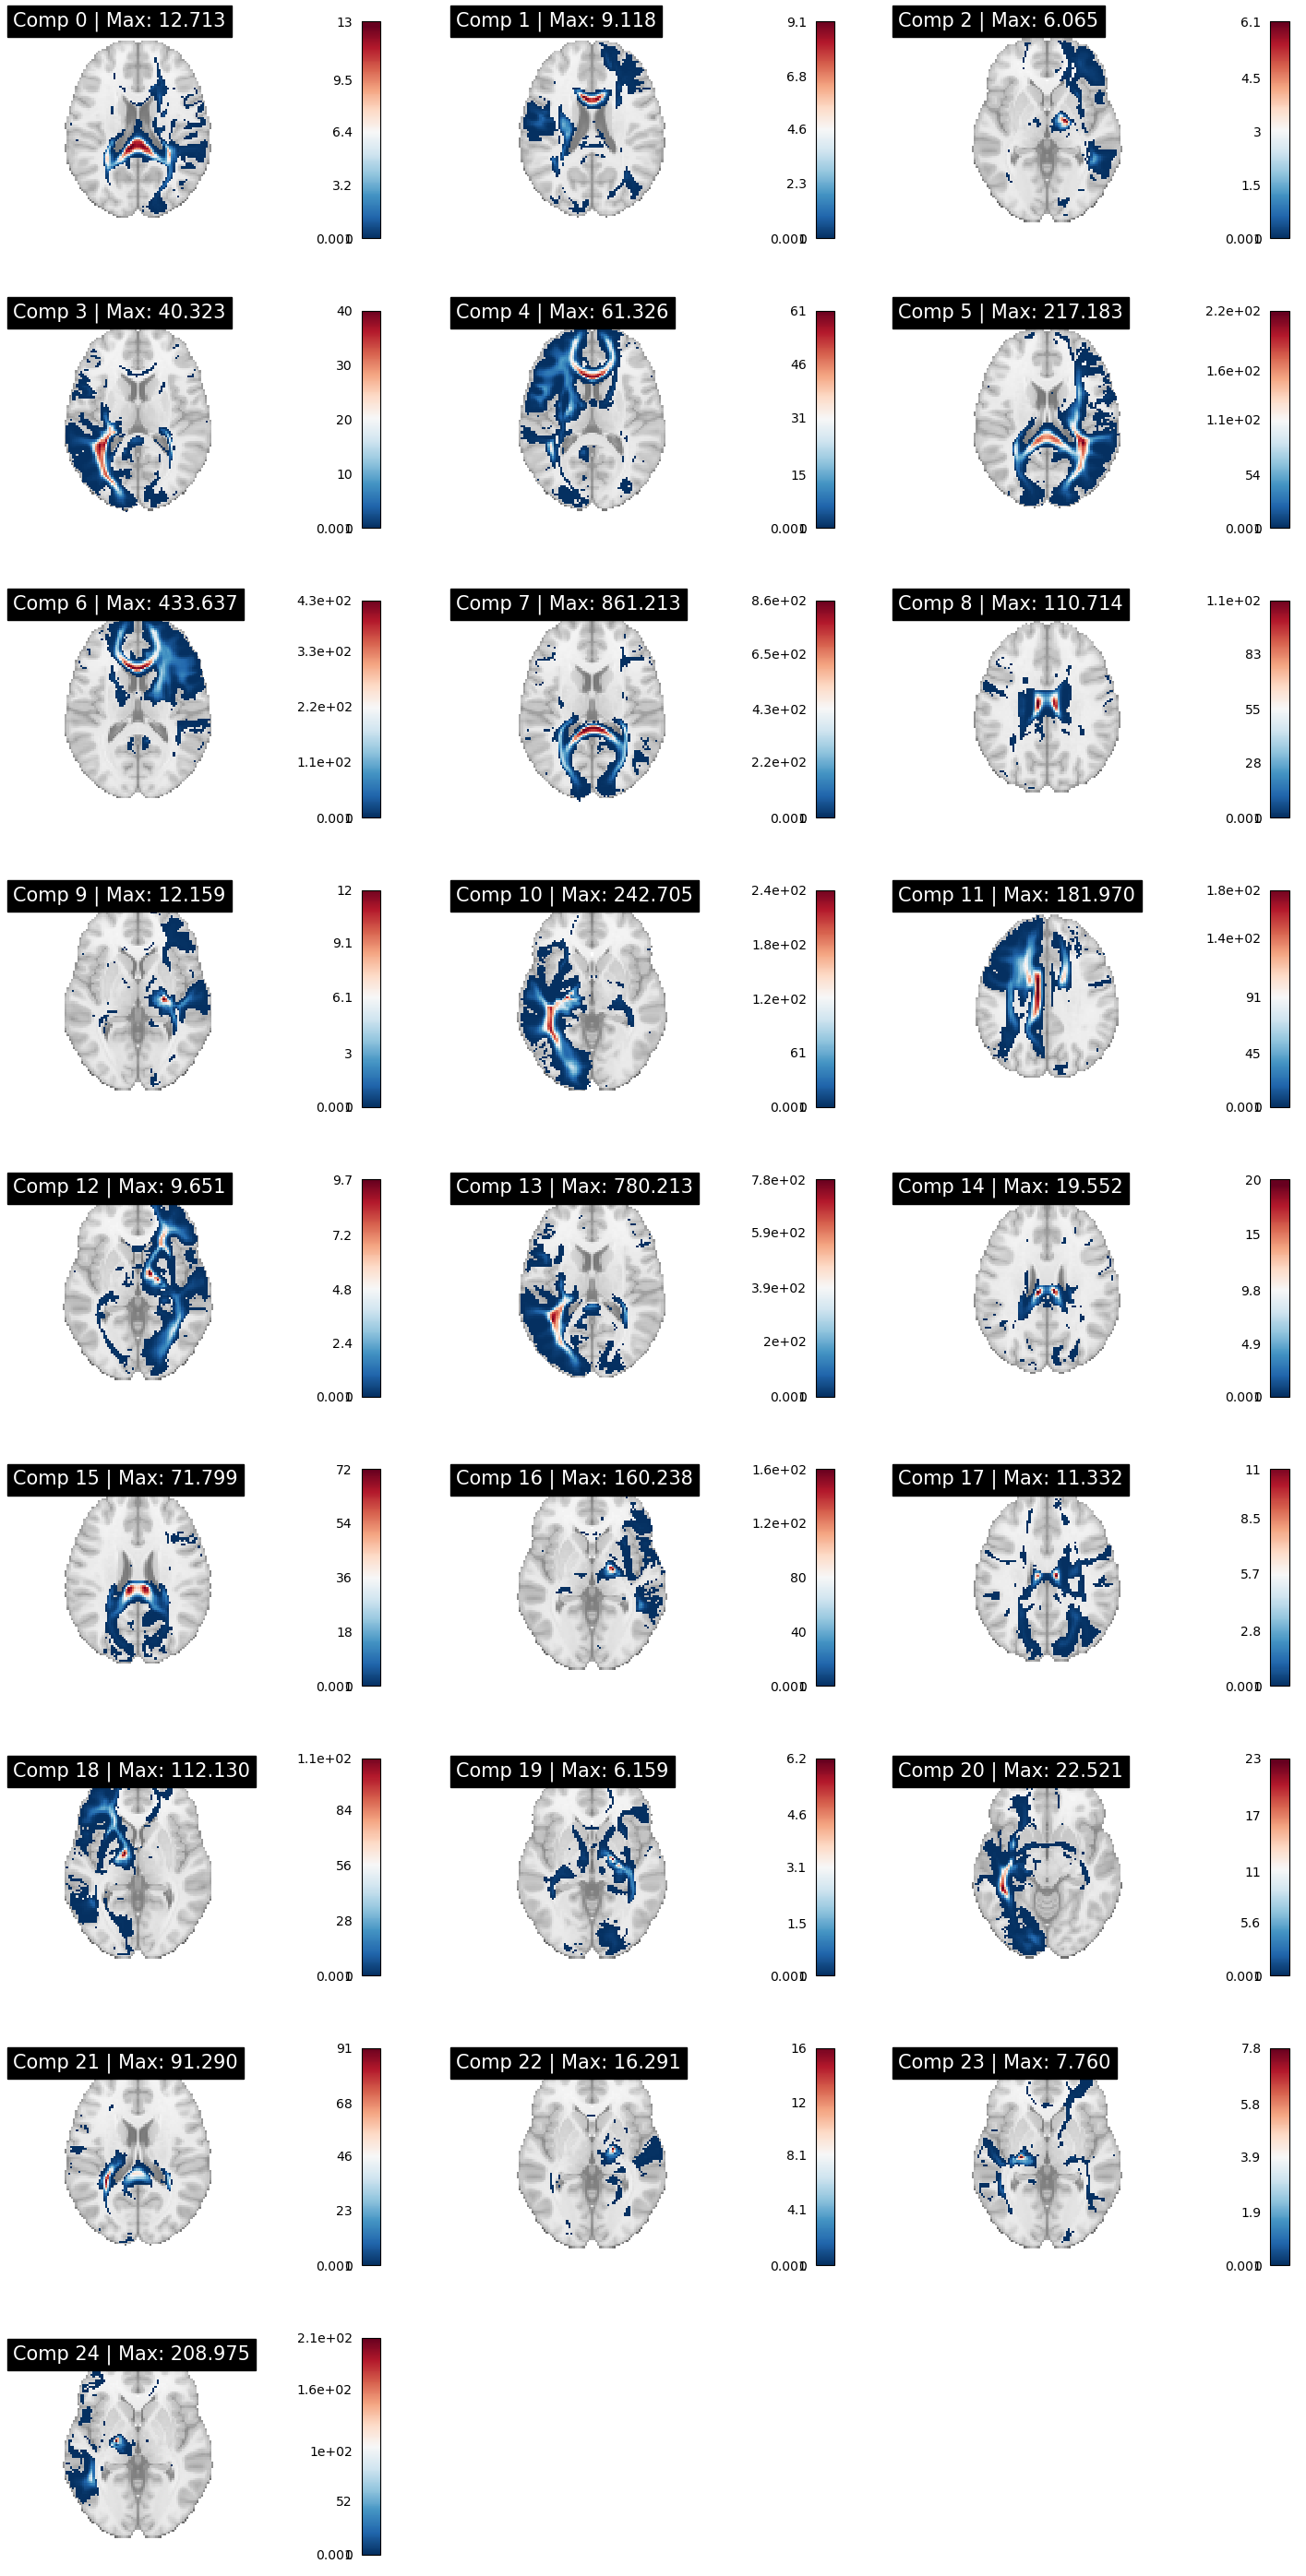

In [25]:
import matplotlib.pyplot as plt
from nilearn import image, plotting

img_path = "results/nmf/nmf_loadings_4d.nii.gz"
n_components = 25

n_cols = 3
n_rows = (n_components + n_cols - 1) // n_cols

fig = plt.figure(figsize=(18, 4 * n_rows))

for i in range(n_components):
    comp_img = image.index_img(img_path, i)
    vmax = comp_img.get_fdata().max()
    
    ax = fig.add_subplot(n_rows, n_cols, i + 1)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Comp {i} | Max: {vmax:.3f}", 
        threshold=0.001,
        axes=ax, 
        colorbar=True,
        display_mode='z', 
        cut_coords=1,
        annotate=False
    )

plt.subplots_adjust(hspace=0.3, wspace=0.1)
plotting.show()

# PCA

In [26]:
td_pca = TD_PCA(maps_ucsf, T1, binary_mask=T1_brain, n_components=10)
cmps_ucsf = td_pca.fit_pca_maps(norm=normalization)
thresholds = td_pca.explained_variance_plot(save_dir=save_dir, filename=f'{normalization}_normalized_masked.pdf')

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!


In [27]:
Project = Projections(td_pca)
Project.components_to_brain(save_dir="results/", filename=f"{normalization}_normalized_masked_loadings.nii.gz")

INFO:	Unmasking PCA loadings.
Components shape (4D): (98, 116, 94, 10)
Template shape (3D): (98, 116, 94)
No. of voxels in template shape: 1068592
INFO:	Saved 4D NIfTI PCA components at results/None_normalized_masked_loadings.nii.gz


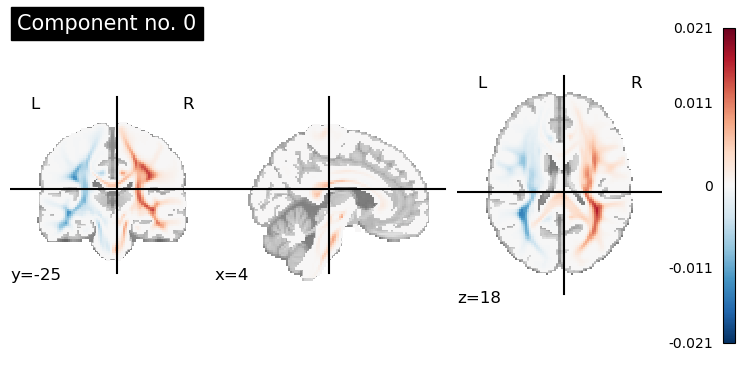

In [29]:
from nilearn import image
from nilearn import plotting


img_path = "results/None_normalized_masked_loadings.nii.gz"
no = 0
fourth_comp = image.index_img(img_path, no)

plotting.plot_stat_map(fourth_comp, title=f"Component no. {no}", colorbar=True)
plotting.show()

In [ ]:
Project = Projections(td_pca)
Project.components_to_brain(save_dir=save_dir, filename=f"{normalization}_normalized_masked_loadings.nii.gz")

INFO:	Unmasking PCA loadings.


In [ ]:
Project.components_to_brain(save_dir=save_dir, filename=f"{normalization}_normalized_masked_loadings.nii.gz")
# explained_all, corrs_all, cos_all = Project.LowRank_convergence(maps_ucsf, cmps_ucsf, max_components=10, n_jobs=-1)

INFO:	Saved 4D NIfTI PCA components at results/None_normalized_masked_loadings.nii.gz
